## 2. Arquitectura ResNet50 mediante transferencia de aprendizaje

Se utilizará ResNet50 con pesos preentrenados en ImageNet.

Inicialmente se congelarán las capas convolucionales
y se reemplazará la capa final por una capa de cinco
neuronas, correspondientes a los estados de maduración.

Esta estrategia permitirá entrenar inicialmente
solo el clasificador, reduciendo el costo computacional.

In [2]:
import torch

# Configurar el dispositivo de entrenamiento
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo seleccionado:", device)

Dispositivo seleccionado: cpu


In [3]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Seleccionar pesos preentrenados
pesos = ResNet50_Weights.DEFAULT

# Cargar ResNet50
modelo = resnet50(weights=pesos)

# Congelar las capas originales
for parametro in modelo.parameters():
    parametro.requires_grad = False

# Obtener número de características de la capa final
num_caracteristicas = modelo.fc.in_features

# Reemplazar clasificador por cinco salidas
modelo.fc = nn.Linear(num_caracteristicas, 5)

# Enviar modelo al dispositivo
modelo = modelo.to(device)

print("Modelo: ResNet50")
print("Características de entrada:", num_caracteristicas)
print("Categorías de salida:", modelo.fc.out_features)

print(
    "Parámetros entrenables:",
    sum(p.numel() for p in modelo.parameters() if p.requires_grad)
)

print("Dispositivo:", device)

Modelo: ResNet50
Características de entrada: 2048
Categorías de salida: 5
Parámetros entrenables: 10245
Dispositivo: cpu


## 3. Preparación del dataset para ResNet50

Se utilizará el Mango Shelf-Life Dataset, compuesto por
4,428 imágenes distribuidas en cinco estados de maduración.

Se respetará la división estratificada realizada previamente:

- Entrenamiento: 3,099 imágenes (70 %)
- Validación: 664 imágenes (15 %)
- Prueba: 665 imágenes (15 %)

Las imágenes serán transformadas a tensores compatibles
con ResNet50 preentrenado en ImageNet.

In [4]:
import pandas as pd
from pathlib import Path

# Directorio principal del proyecto
proyecto = Path.cwd().resolve().parent

# Archivo original
origen = proyecto / "resultados" / "division_dataset_preliminar.csv"

# Archivo definitivo
destino = proyecto / "resultados" / "division_dataset.csv"

# Cargar CSV
df = pd.read_csv(origen)

# Obtener ruta relativa comenzando desde data/
def convertir_ruta(ruta):
    ruta = str(ruta).replace("\\", "/")
    posicion = ruta.lower().find("/data/")

    if posicion == -1:
        raise ValueError(f"Ruta sin carpeta data/: {ruta}")

    return ruta[posicion + 1:]

# Convertir rutas
df["ruta"] = df["ruta"].apply(convertir_ruta)

# Guardar CSV portable
df.to_csv(destino, index=False, encoding="utf-8-sig")

# Verificar que existen las imágenes
existentes = df["ruta"].apply(
    lambda ruta: (proyecto / ruta).is_file()
)

print("CSV creado:", destino.name)
print("Total de imágenes:", len(df))
print("Imágenes encontradas:", existentes.sum())
print("Imágenes faltantes:", (~existentes).sum())

print("\nDistribución:")
print(df["conjunto"].value_counts())

print("\nPrimeras rutas:")
print(df[["ruta", "clase", "conjunto"]].head(3))

CSV creado: division_dataset.csv
Total de imágenes: 4428
Imágenes encontradas: 4428
Imágenes faltantes: 0

Distribución:
conjunto
train    3099
test      665
valid     664
Name: count, dtype: int64

Primeras rutas:
                                                ruta   clase conjunto
0  data/entrenamiento/Mango Shelf-Life Dataset/Un...  Unripe    train
1  data/entrenamiento/Mango Shelf-Life Dataset/Un...  Unripe    train
2  data/entrenamiento/Mango Shelf-Life Dataset/Un...  Unripe    train


## 4. Implementación de Dataset y DataLoader en PyTorch

Se implementará una clase personalizada MangoDataset para
cargar las imágenes y sus etiquetas de maduración.

Se utilizarán transformaciones compatibles con ResNet50
preentrenado en ImageNet.

Los datos se cargarán mediante DataLoader utilizando lotes
de 16 imágenes, considerando el entrenamiento con CPU.

Los conjuntos de entrenamiento, validación y prueba
permanecerán separados.

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.models import ResNet50_Weights
from PIL import Image

# Mantener un orden fijo de categorías
clases = [
    "Unripe",
    "Semiripe",
    "Fully Ripe",
    "Overripe",
    "Perished"
]

clase_a_indice = {
    clase: i for i, clase in enumerate(clases)
}

# Preprocesamiento de ResNet50
transformaciones = ResNet50_Weights.DEFAULT.transforms()

class MangoDataset(Dataset):

    def __init__(self, dataframe, directorio, transform=None):
        self.datos = dataframe.reset_index(drop=True)
        self.directorio = Path(directorio)
        self.transform = transform

    def __len__(self):
        return len(self.datos)

    def __getitem__(self, indice):
        fila = self.datos.iloc[indice]

        ruta = self.directorio / fila["ruta"]

        with Image.open(ruta) as imagen:
            imagen = imagen.convert("RGB")

            if self.transform:
                imagen = self.transform(imagen)

        etiqueta = clase_a_indice[fila["clase"]]

        return imagen, etiqueta

print("Clase MangoDataset creada correctamente.")

Clase MangoDataset creada correctamente.


In [7]:
# Separar los registros
df_train = df[df["conjunto"] == "train"]
df_valid = df[df["conjunto"] == "valid"]
df_test = df[df["conjunto"] == "test"]

# Crear datasets
train_dataset = MangoDataset(
    df_train, proyecto, transformaciones
)

valid_dataset = MangoDataset(
    df_valid, proyecto, transformaciones
)

test_dataset = MangoDataset(
    df_test, proyecto, transformaciones
)

# Configuración para CPU
batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DATASET PREPARADO")
print("-" * 40)
print("Entrenamiento:", len(train_dataset))
print("Validación:", len(valid_dataset))
print("Prueba:", len(test_dataset))

print("\nLotes por época:")
print("Train:", len(train_loader))
print("Valid:", len(valid_loader))
print("Test:", len(test_loader))

DATASET PREPARADO
----------------------------------------
Entrenamiento: 3099
Validación: 664
Prueba: 665

Lotes por época:
Train: 194
Valid: 42
Test: 42


In [8]:
imagenes, etiquetas = next(iter(train_loader))

print("Dimensión del lote:", imagenes.shape)
print("Dimensión de etiquetas:", etiquetas.shape)
print("Etiquetas del primer lote:", etiquetas.tolist())

Dimensión del lote: torch.Size([16, 3, 224, 224])
Dimensión de etiquetas: torch.Size([16])
Etiquetas del primer lote: [2, 1, 0, 1, 3, 0, 1, 1, 1, 3, 3, 0, 0, 3, 2, 0]


## 5. Configuración del entrenamiento de ResNet50

Se utilizará transferencia de aprendizaje con ResNet50,
preentrenado en ImageNet.

Configuración inicial:
- Función de pérdida: CrossEntropyLoss
- Optimizador: Adam
- Tasa de aprendizaje: 0.001
- Tamaño de lote: 16
- Dispositivo: CPU
- Épocas iniciales: 3

Se entrenará únicamente la capa de clasificación final.

Esta fase permitirá verificar el funcionamiento del modelo
antes de realizar experimentos más extensos.

In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet50, ResNet50_Weights

# Reproducibilidad
torch.manual_seed(42)

# Dispositivo
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Cargar ResNet50 preentrenado
modelo = resnet50(weights=ResNet50_Weights.DEFAULT)

# Congelar las capas originales
for parametro in modelo.parameters():
    parametro.requires_grad = False

# Adaptar la última capa a cinco categorías
num_caracteristicas = modelo.fc.in_features
modelo.fc = nn.Linear(num_caracteristicas, 5)

modelo = modelo.to(device)

# Función de pérdida
criterio = nn.CrossEntropyLoss()

# Optimizador: solamente parámetros entrenables
optimizador = optim.Adam(
    modelo.fc.parameters(),
    lr=0.001
)

# Configuración
epocas = 3

print("CONFIGURACIÓN DEL ENTRENAMIENTO")
print("-" * 45)
print("Modelo: ResNet50")
print("Dispositivo:", device)
print("Función de pérdida: CrossEntropyLoss")
print("Optimizador: Adam")
print("Learning rate: 0.001")
print("Épocas:", epocas)
print("Batch size:", batch_size)

print(
    "Parámetros entrenables:",
    sum(p.numel() for p in modelo.parameters() if p.requires_grad)
)

CONFIGURACIÓN DEL ENTRENAMIENTO
---------------------------------------------
Modelo: ResNet50
Dispositivo: cpu
Función de pérdida: CrossEntropyLoss
Optimizador: Adam
Learning rate: 0.001
Épocas: 3
Batch size: 16
Parámetros entrenables: 10245


In [11]:
historial = {
    "train_loss": [],
    "train_acc": [],
    "valid_loss": [],
    "valid_acc": []
}

In [12]:
import time

for epoca in range(epocas):

    inicio = time.time()

    modelo.eval()  # Mantener BatchNorm congelado
    perdida_total = 0
    aciertos = 0
    total = 0

    print(f"\nIniciando época {epoca + 1}/{epocas}", flush=True)

    for numero_lote, (imagenes, etiquetas) in enumerate(train_loader):

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizador.zero_grad()

        salidas = modelo(imagenes)
        perdida = criterio(salidas, etiquetas)

        perdida.backward()
        optimizador.step()

        perdida_total += perdida.item() * imagenes.size(0)
        aciertos += (salidas.argmax(1) == etiquetas).sum().item()
        total += etiquetas.size(0)

        # Mostrar progreso cada 20 lotes
        if (numero_lote + 1) % 20 == 0:
            print(
                f"Lote {numero_lote + 1}/{len(train_loader)} "
                f"| Loss: {perdida.item():.4f}",
                flush=True
            )

    train_loss = perdida_total / total
    train_acc = aciertos / total

    historial["train_loss"].append(train_loss)
    historial["train_acc"].append(train_acc)

    print(f"\nÉPOCA {epoca + 1} FINALIZADA")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Tiempo: {(time.time() - inicio) / 60:.2f} minutos")


Iniciando época 1/3
Lote 20/194 | Loss: 1.2613
Lote 40/194 | Loss: 0.9186
Lote 60/194 | Loss: 1.1018
Lote 80/194 | Loss: 0.6390
Lote 100/194 | Loss: 0.9455
Lote 120/194 | Loss: 0.7583
Lote 140/194 | Loss: 0.6233
Lote 160/194 | Loss: 0.5115
Lote 180/194 | Loss: 0.7368

ÉPOCA 1 FINALIZADA
Train Loss: 0.8568
Train Accuracy: 0.7231
Tiempo: 12.00 minutos

Iniciando época 2/3
Lote 20/194 | Loss: 0.4346
Lote 40/194 | Loss: 0.5978
Lote 60/194 | Loss: 0.5564
Lote 80/194 | Loss: 0.5997
Lote 100/194 | Loss: 0.4641
Lote 120/194 | Loss: 0.3770
Lote 140/194 | Loss: 0.5324
Lote 160/194 | Loss: 0.5116
Lote 180/194 | Loss: 0.4248

ÉPOCA 2 FINALIZADA
Train Loss: 0.5260
Train Accuracy: 0.8151
Tiempo: 12.07 minutos

Iniciando época 3/3
Lote 20/194 | Loss: 0.2434
Lote 40/194 | Loss: 0.3942
Lote 60/194 | Loss: 0.5393
Lote 80/194 | Loss: 0.3373
Lote 100/194 | Loss: 0.5074
Lote 120/194 | Loss: 0.2875
Lote 140/194 | Loss: 0.5668
Lote 160/194 | Loss: 0.5034
Lote 180/194 | Loss: 0.4572

ÉPOCA 3 FINALIZADA
Train

## 7. Validación del modelo ResNet50

Se evaluará el modelo entrenado durante tres épocas
utilizando 664 imágenes del conjunto de validación.

Se calcularán:
- Validation Loss
- Validation Accuracy

Durante la validación no se actualizarán los parámetros
del modelo.

El conjunto de prueba de 665 imágenes permanecerá
reservado para la evaluación final.

In [14]:
import torch

# Activar modo evaluación
modelo.eval()

perdida_valid = 0.0
aciertos_valid = 0
total_valid = 0

# Desactivar el cálculo de gradientes
with torch.inference_mode():

    for imagenes, etiquetas in valid_loader:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        # Predicciones del modelo
        salidas = modelo(imagenes)

        # Calcular pérdida
        perdida = criterio(salidas, etiquetas)

        perdida_valid += perdida.item() * imagenes.size(0)

        # Obtener clase predicha
        predicciones = salidas.argmax(dim=1)

        aciertos_valid += (
            predicciones == etiquetas
        ).sum().item()

        total_valid += etiquetas.size(0)

# Calcular métricas
valid_loss = perdida_valid / total_valid
valid_acc = aciertos_valid / total_valid

print("RESULTADOS DE VALIDACIÓN - RESNET50")
print("-" * 45)

print(f"Imágenes evaluadas: {total_valid}")
print(f"Validation Loss: {valid_loss:.4f}")
print(f"Validation Accuracy: {valid_acc:.4f}")
print(f"Validation Accuracy (%): {valid_acc * 100:.2f}%")

RESULTADOS DE VALIDACIÓN - RESNET50
---------------------------------------------
Imágenes evaluadas: 664
Validation Loss: 0.4477
Validation Accuracy: 0.8178
Validation Accuracy (%): 81.78%


In [15]:
# Registrar la validación correspondiente a la época 3
historial["valid_loss"] = [valid_loss]
historial["valid_acc"] = [valid_acc]

print("Métricas registradas correctamente.")

Métricas registradas correctamente.


## 8. Almacenamiento del modelo ResNet50

Se guardará el modelo entrenado durante tres épocas,
incluyendo sus pesos, configuración y métricas obtenidas.

Esto permitirá recuperar el modelo sin repetir el
entrenamiento y realizar evaluaciones posteriores.

In [16]:
import torch
from pathlib import Path

ruta_modelos = proyecto / "modelos"
ruta_modelos.mkdir(parents=True, exist_ok=True)

ruta_modelo = ruta_modelos / "resnet50_mango_baseline.pth"

checkpoint = {
    "modelo": "ResNet50",
    "model_state_dict": modelo.state_dict(),
    "optimizer_state_dict": optimizador.state_dict(),
    "epocas": 3,
    "clases": clases,
    "train_accuracy": 0.8509,
    "train_loss": 0.4315,
    "valid_accuracy": valid_acc,
    "valid_loss": valid_loss,
    "batch_size": batch_size,
    "learning_rate": 0.001
}

torch.save(checkpoint, ruta_modelo)

print("MODELO GUARDADO CORRECTAMENTE")
print("-" * 45)
print("Archivo:", ruta_modelo.name)
print("Ubicación:", ruta_modelo)
print("Tamaño (MB):", round(ruta_modelo.stat().st_size / 1024**2, 2))

MODELO GUARDADO CORRECTAMENTE
---------------------------------------------
Archivo: resnet50_mango_baseline.pth
Ubicación: D:\ronex_pozo\CLASES\Cursos 2026 - II\Metodologia de la investigacion\Mango_Madurez_ML\modelos\resnet50_mango_baseline.pth
Tamaño (MB): 90.1


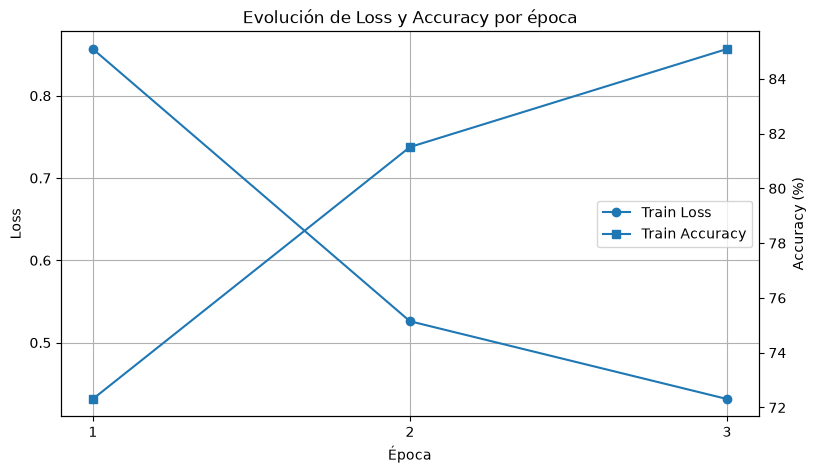

In [17]:
import matplotlib.pyplot as plt

# Datos
epocas_eje = [1, 2, 3]
train_loss = [0.8568, 0.5260, 0.4315]
train_acc = [0.7231, 0.8151, 0.8509]  # en proporción

# Crear figura
fig, ax1 = plt.subplots(figsize=(9, 5))

# Gráfico de loss
ax1.plot(epocas_eje, train_loss, marker="o", label="Train Loss")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.set_xticks(epocas_eje)
ax1.grid(True)

# Segundo eje para accuracy
ax2 = ax1.twinx()
ax2.plot(epocas_eje, [x * 100 for x in train_acc], marker="s", label="Train Accuracy")
ax2.set_ylabel("Accuracy (%)")

# Título
plt.title("Evolución de Loss y Accuracy por época")

# Unir leyendas de ambos ejes
lineas1, etiquetas1 = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()
ax1.legend(lineas1 + lineas2, etiquetas1 + etiquetas2, loc="center right")

plt.show()

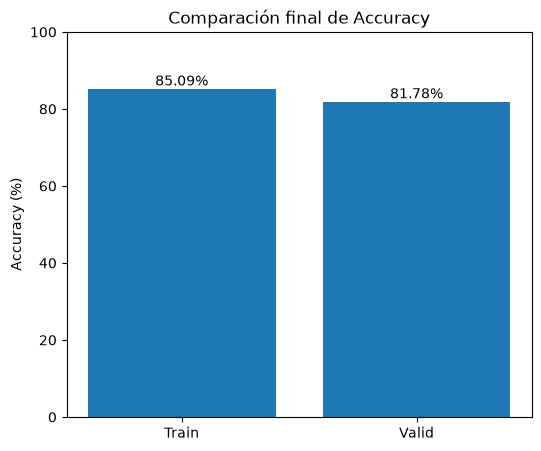

In [18]:
etiquetas = ["Train", "Valid"]
valores_acc = [0.8509 * 100, 0.8178 * 100]

plt.figure(figsize=(6, 5))
plt.bar(etiquetas, valores_acc)
plt.title("Comparación final de Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, valor in enumerate(valores_acc):
    plt.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.show()

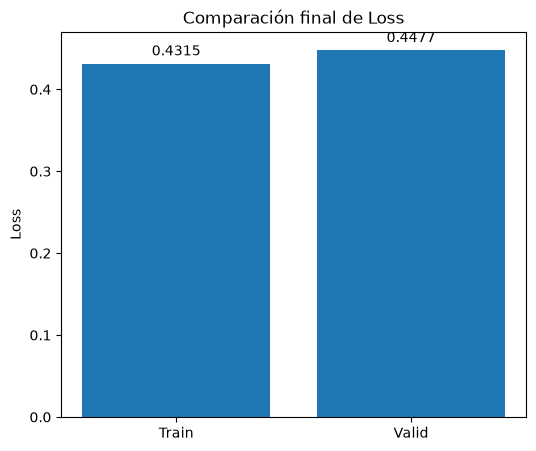

In [19]:
etiquetas = ["Train", "Valid"]
valores_loss = [0.4315, 0.4477]

plt.figure(figsize=(6, 5))
plt.bar(etiquetas, valores_loss)
plt.title("Comparación final de Loss")
plt.ylabel("Loss")

for i, valor in enumerate(valores_loss):
    plt.text(i, valor + 0.01, f"{valor:.4f}", ha="center")

plt.show()

## 10. Evaluación del rendimiento por categoría

Se evaluará el modelo ResNet50 mediante las siguientes métricas:

- **Precision:** proporción de predicciones positivas correctas.
- **Recall:** proporción de imágenes correctamente identificadas de cada clase.
- **F1-score:** media armónica entre precision y recall.
- **Support:** cantidad de imágenes reales por categoría.

Se prestará especial atención a la categoría Perished
(deteriorado), debido a su menor representación en el dataset.

La evaluación se realizará con las 664 imágenes de validación.

In [20]:
import torch
from sklearn.metrics import classification_report
import pandas as pd

# Modelo en modo evaluación
modelo.eval()

etiquetas_reales = []
etiquetas_predichas = []

with torch.inference_mode():

    for imagenes, etiquetas in valid_loader:

        imagenes = imagenes.to(device)

        # Predicción
        salidas = modelo(imagenes)
        predicciones = torch.argmax(salidas, dim=1)

        etiquetas_reales.extend(etiquetas.tolist())
        etiquetas_predichas.extend(
            predicciones.cpu().tolist()
        )

print("Imágenes evaluadas:", len(etiquetas_reales))
print("Predicciones generadas:", len(etiquetas_predichas))

Imágenes evaluadas: 664
Predicciones generadas: 664


In [21]:
reporte = classification_report(
    etiquetas_reales,
    etiquetas_predichas,
    labels=list(range(len(clases))),
    target_names=clases,
    digits=4,
    zero_division=0
)

print("REPORTE DE CLASIFICACIÓN - RESNET50")
print("=" * 60)
print(reporte)

REPORTE DE CLASIFICACIÓN - RESNET50
              precision    recall  f1-score   support

      Unripe     0.8356    0.9059    0.8694       202
    Semiripe     0.7857    0.6994    0.7401       173
  Fully Ripe     0.7574    0.8110    0.7833       127
    Overripe     0.8613    0.8806    0.8708       134
    Perished     1.0000    0.6429    0.7826        28

    accuracy                         0.8178       664
   macro avg     0.8480    0.7880    0.8092       664
weighted avg     0.8198    0.8178    0.8158       664



In [22]:
reporte_dict = classification_report(
    etiquetas_reales,
    etiquetas_predichas,
    labels=list(range(len(clases))),
    target_names=clases,
    output_dict=True,
    zero_division=0
)

df_reporte = pd.DataFrame(reporte_dict).transpose()

ruta_reporte = proyecto / "resultados" / "resnet50_reporte_validacion.csv"

df_reporte.to_csv(
    ruta_reporte,
    index=True,
    encoding="utf-8-sig"
)

print("Reporte guardado correctamente:")
print(ruta_reporte)

Reporte guardado correctamente:
D:\ronex_pozo\CLASES\Cursos 2026 - II\Metodologia de la investigacion\Mango_Madurez_ML\resultados\resnet50_reporte_validacion.csv



### 10.1. Interpretación de los resultados de clasificación

El modelo **ResNet50**, entrenado durante 3 épocas mediante transferencia de aprendizaje, alcanzó una exactitud (*accuracy*) del **81.78 %** sobre 664 imágenes de validación, demostrando una capacidad favorable para clasificar los cinco estados de maduración del mango.

**Análisis por categoría:**

- **Unripe (inmaduro):** obtuvo un F1-score de **86.94 %** y un recall de **90.59 %**, evidenciando una buena capacidad para identificar mangos inmaduros.
- **Semiripe (semimaduro):** registró el menor F1-score (**74.01 %**) y un recall de **69.94 %**, indicando mayores dificultades para distinguir esta etapa intermedia.
- **Fully Ripe (maduro):** alcanzó un F1-score de **78.33 %**, mostrando un rendimiento aceptable, aunque con posibles confusiones respecto a estados cercanos.
- **Overripe (sobremaduro):** obtuvo el mayor F1-score (**87.08 %**), siendo la categoría con mejor equilibrio entre precisión y sensibilidad.
- **Perished (deteriorado):** alcanzó una precisión del **100 %**, pero un recall de **64.29 %**. Esto significa que todas las imágenes clasificadas como deterioradas fueron correctas, aunque el modelo solo identificó 18 de las 28 imágenes realmente deterioradas.

**Evaluación general:**

El F1-score macro fue de **80.92 %**, mientras que el F1-score ponderado alcanzó **81.58 %**. Estos resultados indican un rendimiento general favorable, aunque existen diferencias entre categorías, especialmente en *Semiripe* y *Perished*.

**Conclusión:**

ResNet50 demuestra potencial para identificar automáticamente el estado de maduración del mango mediante imágenes digitales. Sin embargo, es necesario mejorar la clasificación de estados intermedios y de la categoría minoritaria *Perished*. Como trabajo posterior, se propone evaluar técnicas de balanceo de clases, aumentación de datos y ajuste fino (*fine-tuning*) del modelo.

Estos resultados corresponden únicamente a la **validación interna del dataset original**, por lo que todavía no permiten establecer su capacidad de generalización a mangos Kent peruanos.


## 11. Matriz de confusión del modelo ResNet50

Se construirá una matriz de confusión para analizar
los aciertos y errores de clasificación en los cinco
estados de maduración del mango.

Se generarán dos representaciones:

- Matriz de confusión con cantidades absolutas.
- Matriz de confusión normalizada por clase (%).

Este análisis permitirá identificar las categorías
que presentan mayores dificultades de reconocimiento.

La evaluación se realiza sobre las 664 imágenes
del conjunto de validación.

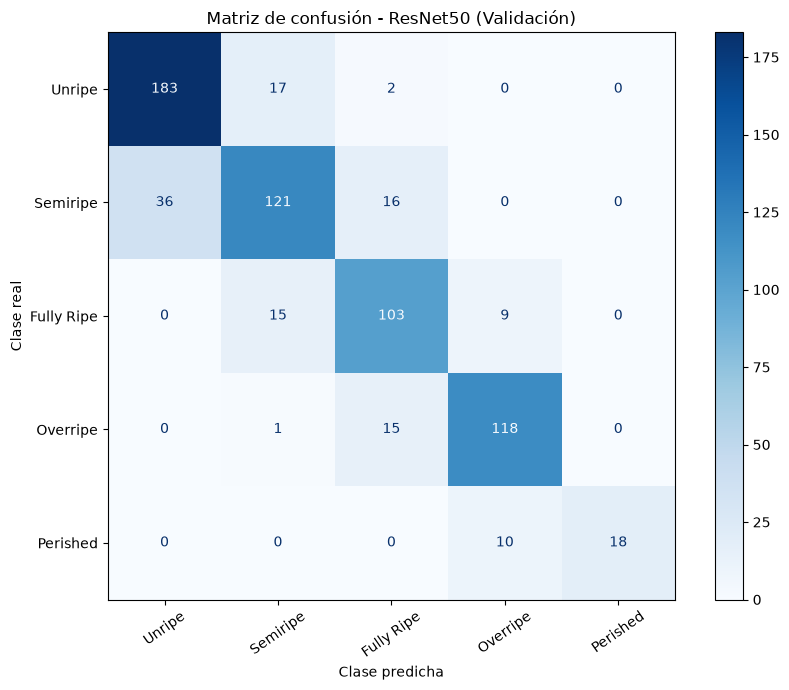

Gráfico guardado en: D:\ronex_pozo\CLASES\Cursos 2026 - II\Metodologia de la investigacion\Mango_Madurez_ML\resultados\resnet50_matriz_confusion_validacion.png


In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ruta_resultados = proyecto / "resultados"
ruta_resultados.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=clases
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title("Matriz de confusión - ResNet50 (Validación)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.xticks(rotation=35)
plt.tight_layout()

ruta_imagen = ruta_resultados / "resnet50_matriz_confusion_validacion.png"

plt.savefig(ruta_imagen, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico guardado en:", ruta_imagen)


### 11.1. Interpretación de la matriz de confusión

La matriz de confusión del modelo ResNet50 muestra **543 predicciones correctas de 664 imágenes de validación**, alcanzando una exactitud del **81.78 %**.

La categoría **Unripe** presentó el mayor recall (90.59 %), identificando correctamente 183 de 202 imágenes. Por otro lado, **Overripe** obtuvo un recall del 88.06 %, con 118 clasificaciones correctas.

La mayor dificultad se observó en **Semiripe**, donde 36 imágenes fueron clasificadas erróneamente como Unripe, lo que evidencia similitudes visuales entre estados consecutivos de maduración.

Asimismo, la categoría **Perished** presentó el menor recall (64.29 %), debido a que 10 de sus 28 imágenes fueron confundidas con Overripe. Este comportamiento podría relacionarse con el desequilibrio del dataset y las similitudes visuales entre frutos sobremaduros y deteriorados.

**Conclusión:** ResNet50 demuestra una capacidad favorable de clasificación; sin embargo, presenta dificultades para diferenciar etapas de maduración visualmente similares. Se recomienda evaluar técnicas de balanceo de clases, aumentación de datos y ajuste fino del modelo para mejorar su capacidad de generalización.


## 12. Evaluación final del modelo ResNet50

Se evaluará el modelo ResNet50 entrenado durante 3 épocas
sobre 665 imágenes del conjunto de prueba (Test).

Este conjunto no fue utilizado durante el entrenamiento
ni la validación.

Métricas:
- Test Loss
- Test Accuracy
- Precision
- Recall
- F1-score macro y ponderado
- Matriz de confusión

El objetivo es evaluar la capacidad de generalización
del modelo en imágenes no utilizadas anteriormente.

In [27]:
import torch
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Modo evaluación: no actualizar parámetros
modelo.eval()

y_true = []
y_pred = []

test_loss_total = 0.0
total_test = 0

with torch.inference_mode():

    for imagenes, etiquetas in test_loader:

        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        salidas = modelo(imagenes)
        perdida = criterio(salidas, etiquetas)

        predicciones = salidas.argmax(dim=1)

        test_loss_total += perdida.item() * imagenes.size(0)
        total_test += imagenes.size(0)

        y_true.extend(etiquetas.cpu().tolist())
        y_pred.extend(predicciones.cpu().tolist())

# Métricas globales
test_loss = test_loss_total / total_test
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("EVALUACIÓN FINAL - RESNET50")
print("=" * 50)
print(f"Imágenes evaluadas: {total_test}")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall: {test_recall:.4f}")
print(f"Macro F1-score: {test_f1:.4f}")

EVALUACIÓN FINAL - RESNET50
Imágenes evaluadas: 665
Test Loss: 0.4344
Test Accuracy: 84.96%
Macro Precision: 0.8754
Macro Recall: 0.8382
Macro F1-score: 0.8539


In [28]:
reporte_test = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(clases))),
    target_names=clases,
    digits=4,
    zero_division=0
)

print("REPORTE FINAL - TEST")
print("=" * 60)
print(reporte_test)

REPORTE FINAL - TEST
              precision    recall  f1-score   support

      Unripe     0.8689    0.8818    0.8753       203
    Semiripe     0.7965    0.7874    0.7919       174
  Fully Ripe     0.8320    0.8254    0.8287       126
    Overripe     0.8794    0.9185    0.8986       135
    Perished     1.0000    0.7778    0.8750        27

    accuracy                         0.8496       665
   macro avg     0.8754    0.8382    0.8539       665
weighted avg     0.8504    0.8496    0.8494       665



In [29]:
from pathlib import Path

ruta_resultados = proyecto / "resultados"
ruta_resultados.mkdir(parents=True, exist_ok=True)

# Guardar métricas generales
metricas_test = pd.DataFrame([{
    "modelo": "ResNet50",
    "epocas": 3,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "macro_precision": test_precision,
    "macro_recall": test_recall,
    "macro_f1": test_f1
}])

metricas_test.to_csv(
    ruta_resultados / "resnet50_metricas_test.csv",
    index=False
)

# Guardar reporte por categoría
reporte_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(clases))),
    target_names=clases,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(reporte_dict).transpose().to_csv(
    ruta_resultados / "resnet50_reporte_test.csv",
    encoding="utf-8-sig"
)

print("Resultados de Test guardados correctamente.")

Resultados de Test guardados correctamente.


## 13. Matriz de confusión final - Test

Se analizarán los resultados del modelo ResNet50 sobre
665 imágenes del conjunto de prueba.

Se utilizará una matriz de confusión para identificar
los aciertos y errores en las cinco categorías de maduración.

Los resultados se guardarán en la carpeta resultados
para documentar la evaluación final del modelo.

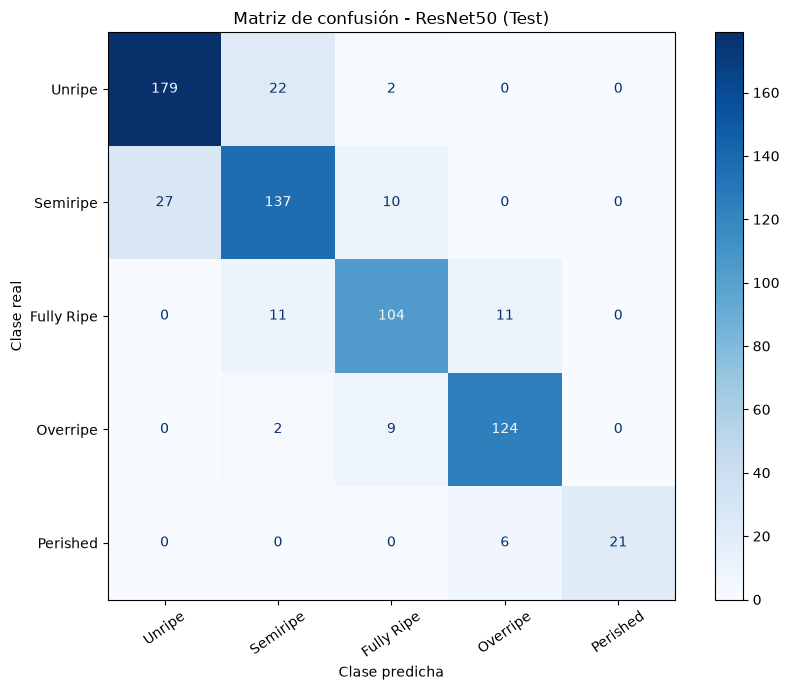

Matriz guardada: D:\ronex_pozo\CLASES\Cursos 2026 - II\Metodologia de la investigacion\Mango_Madurez_ML\resultados\resnet50_matriz_confusion_test.png


In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Verificar que la evaluación Test esté completa
assert len(y_true) == len(y_pred) == 665, \
    "Primero debes ejecutar la evaluación de Test."

# Calcular matriz de confusión
matriz_test = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(clases)))
)

# Crear gráfico
fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_test,
    display_labels=clases
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title("Matriz de confusión - ResNet50 (Test)")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

plt.xticks(rotation=35)
plt.tight_layout()

# Guardar gráfico
ruta_imagen = proyecto / "resultados" / "resnet50_matriz_confusion_test.png"

plt.savefig(ruta_imagen, dpi=300, bbox_inches="tight")
plt.show()

print("Matriz guardada:", ruta_imagen)


### 13.1. Interpretación de la matriz de confusión final

El modelo ResNet50, entrenado mediante transferencia de aprendizaje durante tres épocas, alcanzó una exactitud del **84.96 %** sobre 665 imágenes de prueba, clasificando correctamente 565 imágenes.

Los mejores resultados de sensibilidad se obtuvieron en las categorías Overripe (91.85 %) y Unripe (88.18 %). La mayor confusión ocurrió entre Unripe y Semiripe, con 49 errores entre ambas categorías.

La clase Perished obtuvo un recall del 77.78 %, identificando correctamente 21 de 27 imágenes. Aunque este resultado supera el 64.29 % obtenido durante la validación, continúa existiendo dificultad para diferenciar mangos deteriorados de sobremaduros.

**Conclusión:** ResNet50 presenta un rendimiento favorable para clasificar los cinco estados de maduración del mango. Sin embargo, las confusiones entre categorías consecutivas evidencian la necesidad de evaluar técnicas de ajuste fino, aumentación de datos y balanceo de clases.

Estos resultados corresponden a la evaluación interna con el dataset original y no constituyen todavía una validación externa con mangos Kent peruanos.
